In [1178]:
import numpy as np
from numpy.random import randn
from scipy.linalg import sqrtm, inv
import matplotlib.pyplot as plt
np.random.seed(273)

In [1179]:
def epsilon_and_nu(P: float, Sigma: np.ndarray):
    nu = 1/ (2 * np.pi * np.sqrt(np.linalg.det(Sigma)))
    epsilon = (1-P) * nu

    return epsilon, nu

def in_error_ellipse(x: np.ndarray, mu: np.ndarray, Sigma: np.ndarray, P=0.95):
    epsilon, nu = epsilon_and_nu(P, Sigma)
    rhs = -2*np.log(epsilon / nu)   # = -2 log(1-P)
    lhs = (x - mu).T @ np.linalg.inv(Sigma) @ (x - mu)
    return lhs <= rhs
    
def plot_gaussian(mu, Sigma, N, show=True):
    x_arr = randn(N,2) @ sqrtm(Sigma) + mu

    x_in = np.array([x for x in x_arr if in_error_ellipse(x, mu, Sigma)])
    x_out = np.array([x for x in x_arr if not in_error_ellipse(x, mu, Sigma)])

    e, _ = epsilon_and_nu(0.95, Sigma)
    print(f"Percentage of points in ellipse {len(x_in) / N * 100}")
    plt.scatter(x_in[:,0], x_in[:,1], marker='.')
    plt.scatter(x_out[:,0], x_out[:,1], marker='.')
    plt.title("95% Confidence Error Ellipse")
    if show:
        plt.show()

def get_ellipse_points(mu: np.ndarray, Sigma: np.ndarray, P=0.95, N=200):
    t = np.linspace(0, 2*np.pi, N)
    circle = np.vstack((np.cos(t), np.sin(t)))
    rhs = -2*np.log(1-P)
    ellipse = np.sqrt(rhs) * circle
    scaled_ellipse = sqrtm(Sigma) @ ellipse # circle -> ellipse
    return scaled_ellipse + mu.reshape(2,1)

## Problem 1

### Finding mu_x_y

In [1180]:
mu_x = np.array([0, 0]).reshape((2,1))
mu_y = np.array([0, 0]).reshape((2,1))

Sigma_xx = np.array([
    [0.7, 0.73], 
    [0.73, 1.1]])
Sigma_yy = np.array([
    [0.7, 0.19], 
    [0.19, 0.16]])
Sigma_xy = np.array([
    [0.63, 0.23], 
    [0.72, 0.31]])
Sigma_yy_inv = inv(Sigma_yy)
Sigma_yx = Sigma_xy.T

y = np.array([0.27, 0.62]).reshape((2,1))

print(Sigma_yy_inv)
print(Sigma_yx)

[[ 2.108  -2.5033]
 [-2.5033  9.2227]]
[[0.63 0.72]
 [0.23 0.31]]


In [1181]:
mu_x_y = mu_x + Sigma_xy @ Sigma_yy_inv @ (y - mu_y)
Sigma_x_y = Sigma_xx - Sigma_xy @ Sigma_yy_inv @ Sigma_yx

print(mu_x_y)
print(Sigma_x_y)

[[0.5405]
 [0.8554]]
[[0.1009 0.0197]
 [0.0197 0.2384]]


### Plotting

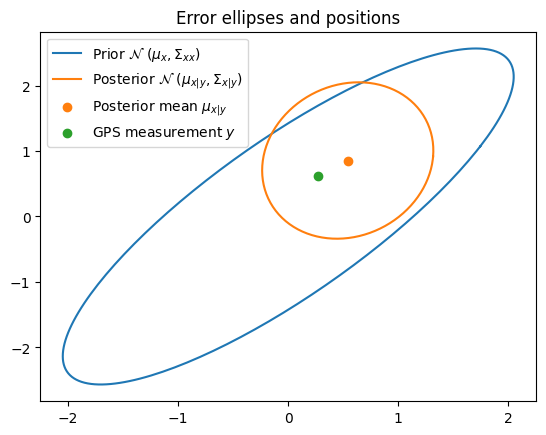

In [1182]:
plt.plot(*get_ellipse_points(mu_x, Sigma_xx), color='tab:blue', label=r"Prior $\cal{N}$ $(\mu_x, \Sigma_{xx})$")

plt.plot(*get_ellipse_points(mu_x_y, Sigma_x_y), color='tab:orange', label=r"Posterior $\cal{N}$ $(\mu_{x|y}, \Sigma_{x|y})$")
plt.scatter(*mu_x_y, color='tab:orange', label=r"Posterior mean $\mu_{x|y}$")

plt.scatter(*y, color='tab:green', label="GPS measurement $y$")

plt.legend()

plt.title("Error ellipses and positions")

plt.show()

# plt.scatter(*mu_x, color='orange')
# plot_gaussian(mu_x_y, Sigma_x_y, 1000, )


## Problem 3

### Creating trajectories

In [1183]:
dt = 1
# Q = np.zeros((4,4))
# Q[2:4, 2:4] = np.eye(2)

# R = 9*np.eye(2)
Q = np.zeros((6,6))
R = np.zeros((3,3))

def u_input(_):
    # return -2.5 * np.array([
    #     np.cos(0.05*t), np.sin(0.05*t)
    # ])
    return np.array([-1, 0.5, 0.01])


In [1184]:
A = np.zeros((6,6))
A[0:3, 0:3] = np.eye(3)
A[0:3, 3:6] = dt*np.eye(3)
A[3:6, 3:6] = np.eye(3)

B = np.zeros((6,3))
B[3:6, 0:3] = np.eye(3) * dt

C = np.zeros((3,6))
C[0:3, 0:3] = np.eye(3)

x0 = np.array([406, -203, -4.06, 0, 0, 0])

In [1185]:
C

array([[1., 0., 0., 0., 0., 0.],
       [0., 1., 0., 0., 0., 0.],
       [0., 0., 1., 0., 0., 0.]])

In [1186]:
print(C @ x0)

[ 406.   -203.     -4.06]


In [1210]:
def noise_W(Q, seed=None):
    if seed is not None:
        np.random.seed(seed)

    return np.random.multivariate_normal(
        mean=np.zeros(Q.shape[0]),
        cov=Q
    )

def noise_V(R, seed=None):
    if seed is not None:
        np.random.seed(seed)

    return np.random.multivariate_normal(
        mean=np.zeros(R.shape[0]),
        cov=R
    )

print(noise_W(Q))
print(noise_V(R))


[ 0.      0.      0.      0.0824  0.314  -0.2267]
[ 1.8153  4.3816 -4.1649]


In [1188]:
N = 30 # Timesteps of 1 second

class Trajectory:
    def __init__(self, x, u, meas):
        self.x_arr = x
        self.u_arr = u
        self.meas_arr = meas

def one_trajectory(N, Q=Q, R=R, show=True, return_results = True):

    meas_arr = np.zeros((N,3))
    u_arr = np.zeros((N,3))
    x_arr = np.zeros((N,6))


    x_arr[0] = x0
    print(x0)
    meas_arr[0] = C @ x0 + noise_V(R)

    for t in range(N-1):
        u_arr[t] = u_input(t).T

        x_arr[t+1] = A @ x_arr[t] + B @ u_arr[t] + noise_W(Q)
        # print(x_arr[t+1] - x_arr[t])
        meas_arr[t+1] = C @ x_arr[t+1] + noise_V(R)

    
    
    if show:
        dimA = 0
        dimB = 1
        plt.plot(x_arr[:,dimA], x_arr[:,dimB], label="Trajectory", color="tab:orange", zorder=dimA)
        plt.scatter(meas_arr[:,dimA], meas_arr[:,dimB], label="Noisy GPS Measurements", s=4, color="tab:blue", zorder=1)
        plt.scatter([x0[dimA]], [x0[dimB]], color="tab:red", label="Starting Position", s=40, marker="o")
        plt.xlabel("X [m]")
        plt.ylabel("Y [m]")
        plt.title("X vs. Y Position")
        plt.legend(("Trajectory", "Noisy GPS Measurements", "Starting Position"))
        plt.grid()
        plt.show()

        dimA = 1
        dimB = 2
        plt.plot(x_arr[:,dimA], x_arr[:,dimB], label="Trajectory", color="tab:orange", zorder=dimA)
        plt.scatter(meas_arr[:,dimA], meas_arr[:,dimB], label="Noisy GPS Measurements", s=4, color="tab:blue", zorder=1)
        plt.scatter([x0[dimA]], [x0[dimB]], color="tab:red", label="Starting Position", s=40, marker="o")
        plt.xlabel("Y [m]")
        plt.ylabel("Z [m]")
        plt.title("Y vs. Z Position")
        plt.legend(("Trajectory", "Noisy GPS Measurements", "Starting Position"))
        plt.grid()
        plt.show()

        dimA = 0
        dimB = 2
        plt.plot(x_arr[:,dimA], x_arr[:,dimB], label="Trajectory", color="tab:orange", zorder=dimA)
        plt.scatter(meas_arr[:,dimA], meas_arr[:,dimB], label="Noisy GPS Measurements", s=4, color="tab:blue", zorder=1)
        plt.scatter([x0[dimA]], [x0[dimB]], color="tab:red", label="Starting Position", s=40, marker="o")
        plt.xlabel("X [m]")
        plt.ylabel("Z [m]")
        plt.title("X vs. Z Position")
        plt.legend(("Trajectory", "Noisy GPS Measurements", "Starting Position"))
        plt.grid()
        plt.show()
        # plt.show()

    if return_results:
        return Trajectory(x_arr, u_arr, meas_arr)
        


[ 406.   -203.     -4.06    0.      0.      0.  ]


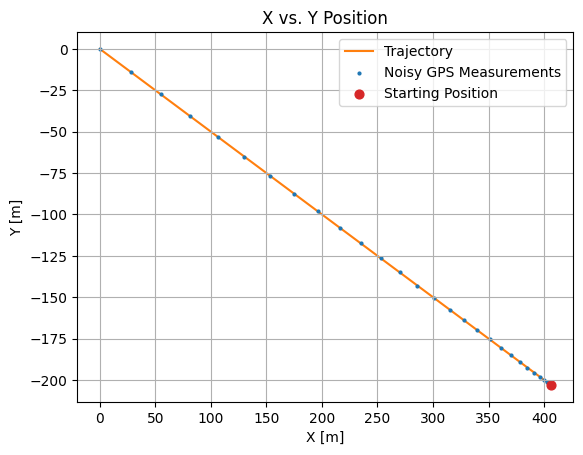

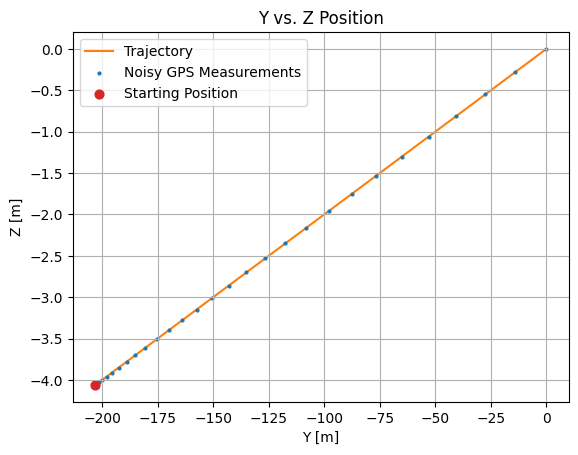

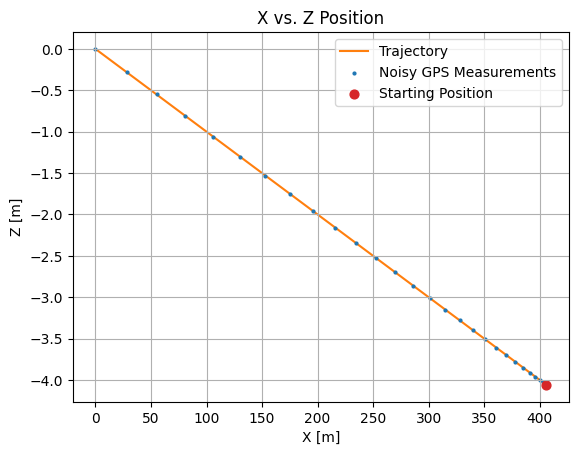

In [1189]:


data_arrs: list[Trajectory] = []
np.random.seed(273)
traj = one_trajectory(30)
# data_arrs.append(one_trajectory(100))
# plt.grid()


Text(0, 0.5, 'Distance [m]')

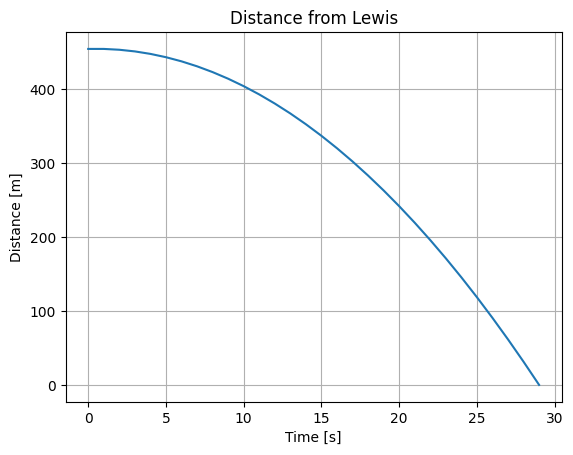

In [1190]:
dist = []
for i in traj.x_arr:
    dist.append(np.linalg.norm(i[:3]))
dist = np.asarray(dist)
plt.plot(dist)
plt.grid()
plt.title("Distance from Lewis")
plt.xlabel("Time [s]")
plt.ylabel("Distance [m]")

[[0.  0.  0.  0.  0.  0. ]
 [0.  0.  0.  0.  0.  0. ]
 [0.  0.  0.  0.  0.  0. ]
 [0.  0.  0.  0.1 0.  0. ]
 [0.  0.  0.  0.  0.1 0. ]
 [0.  0.  0.  0.  0.  0.1]]
[[100.   0.   0.]
 [  0. 100.   0.]
 [  0.   0. 100.]]
[ 406.   -203.     -4.06    0.      0.      0.  ]


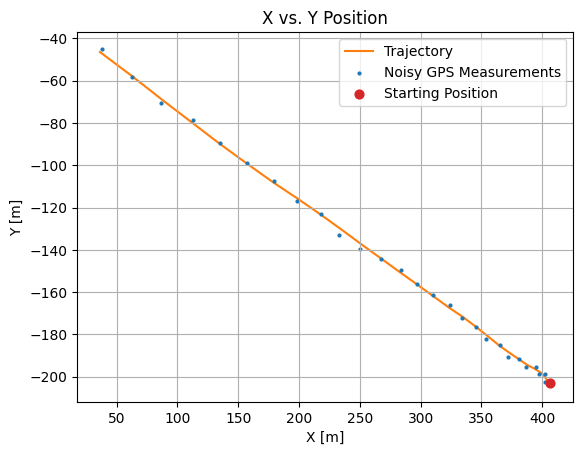

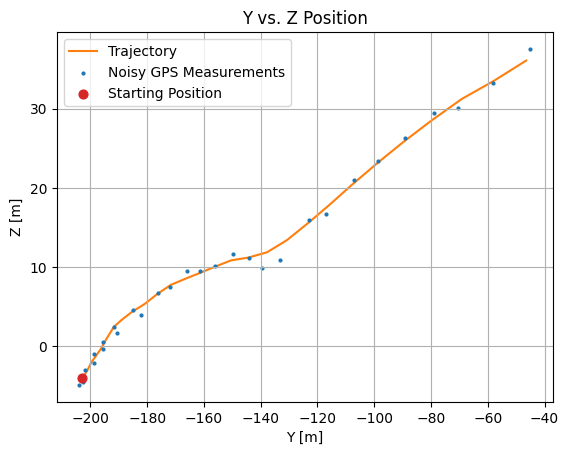

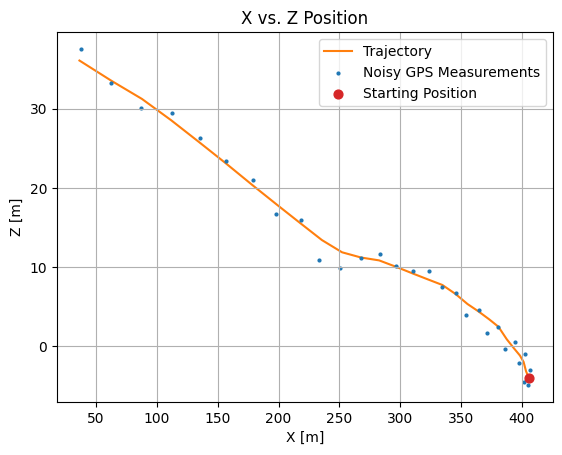

In [1222]:
Q = np.zeros((6,6))
Q[3:6, 3:6] = 0.1*np.eye(3)
Q_OG = Q
# R = 100*np.eye(3)
R = 100*np.eye(3)
# R_OG = R

print(Q)
print(R)
np.random.seed(273)

# traj = one_trajectory(30, Q, R)

# traj = one_trajectory(30, np.zeros((6,6)), np.ones((3,3))) 
# traj = one_trajectory(30, np.zeros((6,6)), 0.1*np.ones((3,3))) 
traj = one_trajectory(30, Q, np.ones((3,3)))

Text(0, 0.5, 'Distance [m]')

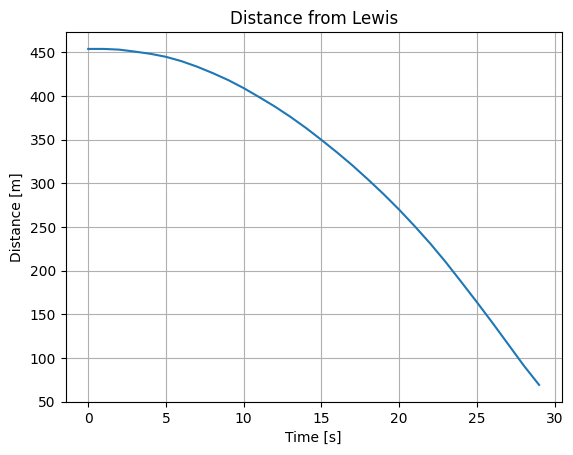

In [1192]:
dist = []
for i in traj.x_arr:
    dist.append(np.linalg.norm(i[:3]))
dist = np.asarray(dist)
plt.plot(dist)
plt.grid()
plt.title("Distance from Lewis")
plt.xlabel("Time [s]")
plt.ylabel("Distance [m]")

### Running Kalman Filter

In [1193]:
mu0 = np.array([406, -203, -4.06, 0, 0, 0])
Sigma0 = np.zeros((6,6))
Sigma0[0:3, 0:3] = 1000*np.eye(3)
Sigma0[3:6, 3:6] = np.eye(3)

In [1194]:
mu_arr = np.zeros((N,6))
Sigma_arr = np.zeros((N,6,6))

mu_arr[0] = mu0
Sigma_arr[0] = Sigma0

x_arr = traj.x_arr
u_arr = traj.u_arr
meas_arr = traj.meas_arr

np.random.seed(273)
for t in range(N-1):
    mu_predict = A @ mu_arr[t] + B @ u_arr[t]
    Sigma_predict = A @ Sigma_arr[t] @ A.T + Q

    K = Sigma_predict @ C.T @ inv(C @ Sigma_predict @ C.T + R)

    mu_arr[t+1] = mu_predict + K @ (meas_arr[t] - C @ mu_predict)
    Sigma_arr[t+1] = Sigma_predict - K @ C @ Sigma_predict


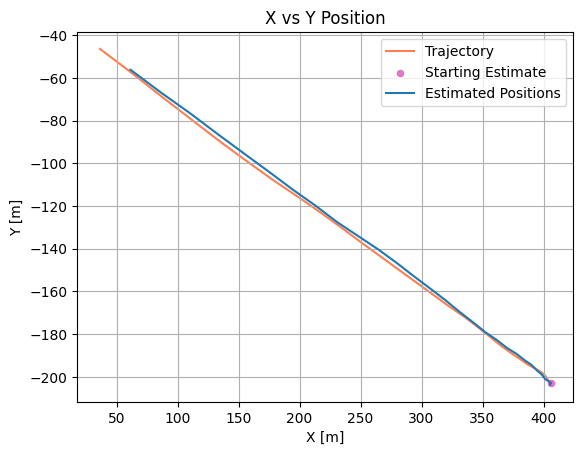

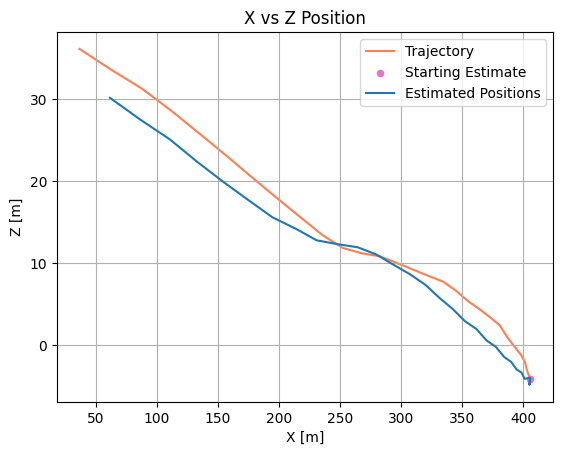

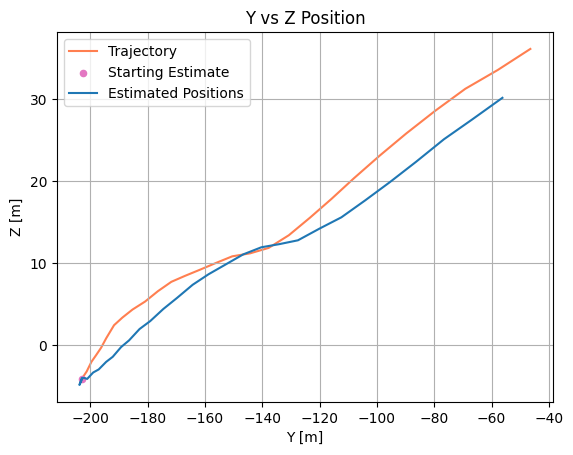

In [1195]:
dimA = 0
dimB = 1
plt.plot(x_arr[:,dimA], x_arr[:,dimB], color="coral", zorder=1)
plt.scatter([mu_arr[0,dimA]], [mu_arr[0,dimB]], color="tab:pink", s=20, marker="o")

mu_dimA = mu_arr[:,dimA]
mu_dimB = mu_arr[:,dimB]
plt.plot(mu_dimA, mu_dimB, color='tab:blue')
# for mu, sigma in zip(mu_arr, Sigma_arr):
#     mu = mu[0:2]
#     sigma = sigma[0:2, 0:2]
#     # plt.plot(*get_ellipse_points(mu, sigma), color='tab:blue')
#     plt.scatter([mu[dimA]], [mu[dimB]], color='tab:blue', s=1)
plt.xlabel("X [m]")
plt.ylabel("Y [m]")
plt.title("X vs Y Position")
plt.grid()
plt.legend(("Trajectory", "Starting Estimate", "Estimated Positions"))
plt.show()

dimA = 0
dimB = 2
plt.plot(x_arr[:,dimA], x_arr[:,dimB], color="coral", zorder=1)
plt.scatter([mu_arr[0,dimA]], [mu_arr[0,dimB]], color="tab:pink", s=20, marker="o")

mu_dimA = mu_arr[:,dimA]
mu_dimB = mu_arr[:,dimB]
plt.plot(mu_dimA, mu_dimB, color='tab:blue')
# for mu, sigma in zip(mu_arr, Sigma_arr):
#     sigma = sigma[0:2, 0:2]
#     # plt.plot(*get_ellipse_points(mu, sigma), color='tab:blue')
#     plt.scatter([mu[dimA]], [mu[dimB]], color='tab:blue', s=1)
plt.xlabel("X [m]")
plt.ylabel("Z [m]")
plt.title("X vs Z Position")
plt.grid()
plt.legend(("Trajectory", "Starting Estimate", "Estimated Positions"))

plt.show()

dimA = 1
dimB = 2
plt.plot(x_arr[:,dimA], x_arr[:,dimB], color="coral", zorder=1)
plt.scatter([mu_arr[0,dimA]], [mu_arr[0,dimB]], color="tab:pink", s=20, marker="o")

mu_dimA = mu_arr[:,dimA]
mu_dimB = mu_arr[:,dimB]
plt.plot(mu_dimA, mu_dimB, color='tab:blue')
# for mu, sigma in zip(mu_arr, Sigma_arr):
#     # mu = mu[0:2]
#     sigma = sigma[0:2, 0:2]
#     # plt.plot(*get_ellipse_points(mu, sigma), color='tab:blue')
#     plt.scatter([mu[dimA]], [mu[dimB]], color='tab:blue', s=1)
plt.xlabel("Y [m]")
plt.ylabel("Z [m]")
plt.title("Y vs Z Position")
plt.grid()
plt.legend(("Trajectory", "Starting Estimate", "Estimated Positions"))
plt.show()

In [1196]:
print(Sigma_arr[-1])

[[22.2689  0.      0.      2.7869  0.      0.    ]
 [ 0.     22.2689  0.      0.      2.7869  0.    ]
 [ 0.      0.     22.2689  0.      0.      2.7869]
 [ 2.7869  0.      0.      0.7991  0.      0.    ]
 [ 0.      2.7869  0.      0.      0.7991  0.    ]
 [ 0.      0.      2.7869  0.      0.      0.7991]]


In [1197]:
mu0_new = np.array([406, -203, -4.06, 0, 0, 0])
# Sigma0_new = np.zeros((6,6)) 
# Sigma0_new[0:3, 0:3] = 1000*np.eye(3)
# Sigma0_new[3:6, 3:6] = np.eye(3)

Sigma0_new = Sigma0*10
# Sigma0_new = Sigma0

In [1198]:
# PART C
# 
# Q_new = Q
Q_new = 10*Q
R_new = 10*R
# R_new = 0.1*np.eye(3)

print(Q_new)
print(R_new)

[[0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 1. 0. 0.]
 [0. 0. 0. 0. 1. 0.]
 [0. 0. 0. 0. 0. 1.]]
[[1000.    0.    0.]
 [   0. 1000.    0.]
 [   0.    0. 1000.]]


In [1199]:
mu_arr = np.zeros((N,6))
Sigma_arr = np.zeros((N,6,6))

mu_arr[0] = mu0
Sigma_arr[0] = Sigma0_new

x_arr = traj.x_arr
u_arr = traj.u_arr
meas_arr = traj.meas_arr


for t in range(N-1):
    mu_predict = A @ mu_arr[t] + B @ u_arr[t]
    Sigma_predict = A @ Sigma_arr[t] @ A.T + Q_new

    K = Sigma_predict @ C.T @ inv(C @ Sigma_predict @ C.T + R_new)

    mu_arr[t+1] = mu_predict + K @ (meas_arr[t] - C @ mu_predict)
    Sigma_arr[t+1] = Sigma_predict - K @ C @ Sigma_predict



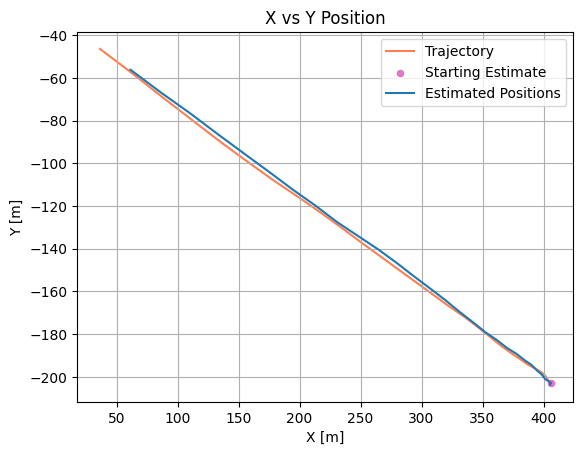

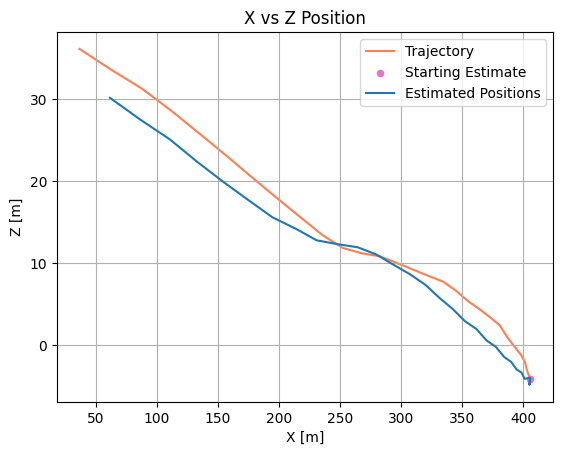

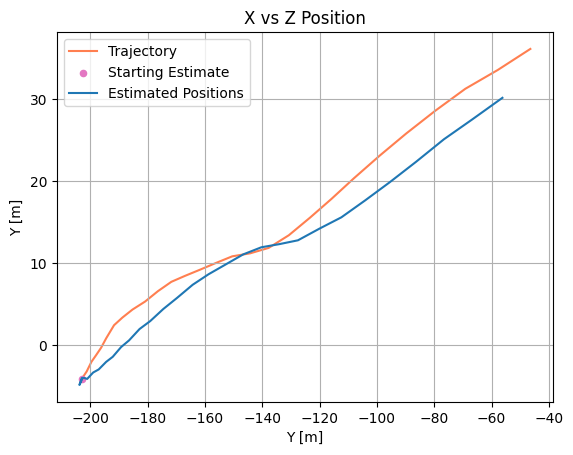

In [1200]:
dimA = 0
dimB = 1
plt.plot(x_arr[:,dimA], x_arr[:,dimB], color="coral", zorder=1)
plt.scatter([mu_arr[0,dimA]], [mu_arr[0,dimB]], color="tab:pink", s=20, marker="o")

mu_dimA = mu_arr[:,dimA]
mu_dimB = mu_arr[:,dimB]
plt.plot(mu_dimA, mu_dimB, color='tab:blue')
# for mu, sigma in zip(mu_arr, Sigma_arr):
#     mu = mu[0:2]
#     sigma = sigma[0:2, 0:2]
#     # plt.plot(*get_ellipse_points(mu, sigma), color='tab:blue')
#     plt.scatter([mu[dimA]], [mu[dimB]], color='tab:blue', s=1)
plt.xlabel("X [m]")
plt.ylabel("Y [m]")
plt.title("X vs Y Position")
plt.grid()
plt.legend(("Trajectory", "Starting Estimate", "Estimated Positions"))
plt.show()

dimA = 0
dimB = 2
plt.plot(x_arr[:,dimA], x_arr[:,dimB], color="coral", zorder=1)
plt.scatter([mu_arr[0,dimA]], [mu_arr[0,dimB]], color="tab:pink", s=20, marker="o")

mu_dimA = mu_arr[:,dimA]
mu_dimB = mu_arr[:,dimB]
plt.plot(mu_dimA, mu_dimB, color='tab:blue')
# for mu, sigma in zip(mu_arr, Sigma_arr):
#     sigma = sigma[0:2, 0:2]
#     # plt.plot(*get_ellipse_points(mu, sigma), color='tab:blue')
#     plt.scatter([mu[dimA]], [mu[dimB]], color='tab:blue', s=1)
plt.xlabel("X [m]")
plt.ylabel("Z [m]")
plt.title("X vs Z Position")
plt.grid()
plt.legend(("Trajectory", "Starting Estimate", "Estimated Positions"))

plt.show()

dimA = 1
dimB = 2
plt.plot(x_arr[:,dimA], x_arr[:,dimB], color="coral", zorder=1)
plt.scatter([mu_arr[0,dimA]], [mu_arr[0,dimB]], color="tab:pink", s=20, marker="o")

mu_dimA = mu_arr[:,dimA]
mu_dimB = mu_arr[:,dimB]
plt.plot(mu_dimA, mu_dimB, color='tab:blue')
# for mu, sigma in zip(mu_arr, Sigma_arr):
#     # mu = mu[0:2]
#     sigma = sigma[0:2, 0:2]
#     # plt.plot(*get_ellipse_points(mu, sigma), color='tab:blue')
#     plt.scatter([mu[dimA]], [mu[dimB]], color='tab:blue', s=1)
plt.xlabel("Y [m]")
plt.ylabel("Y [m]")
plt.title("X vs Z Position")
plt.grid()
plt.legend(("Trajectory", "Starting Estimate", "Estimated Positions"))
plt.show()

In [1201]:
np.set_printoptions(precision=4)
print(Sigma_arr[-1])

[[222.6891   0.       0.      27.8687   0.       0.    ]
 [  0.     222.6891   0.       0.      27.8687   0.    ]
 [  0.       0.     222.6891   0.       0.      27.8687]
 [ 27.8687   0.       0.       7.9914   0.       0.    ]
 [  0.      27.8687   0.       0.       7.9914   0.    ]
 [  0.       0.      27.8687   0.       0.       7.9914]]


[[0.  0.  0.  0.  0.  0. ]
 [0.  0.  0.  0.  0.  0. ]
 [0.  0.  0.  0.  0.  0. ]
 [0.  0.  0.  0.1 0.  0. ]
 [0.  0.  0.  0.  0.1 0. ]
 [0.  0.  0.  0.  0.  0.1]]
[ 406.   -203.     -4.06    0.      0.      0.  ]


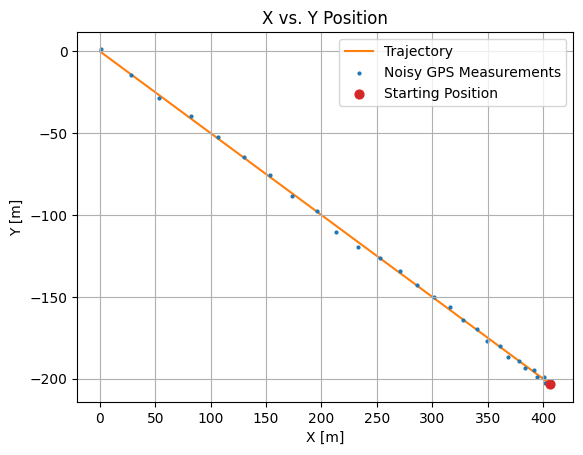

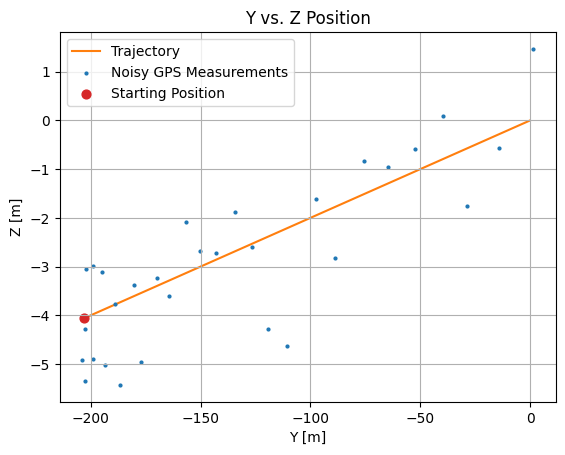

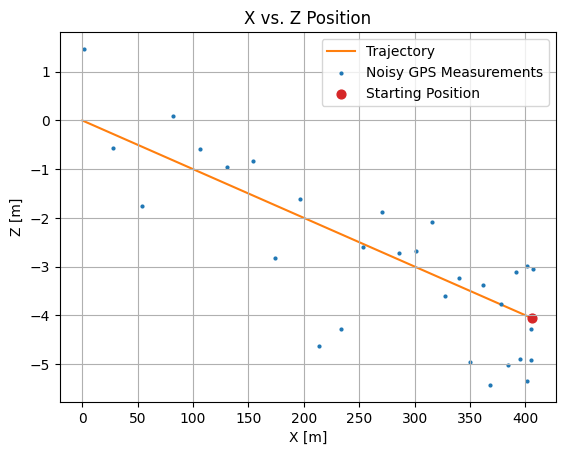

In [1202]:
# PART C
# 

Q_new = Q_OG
# print(Q_OG)
# R_new = 10*R
R_new = 0.1*np.eye(3)
# print(Q_new)
# print(Q_OG)
# print(R_OG)
# print(R_new)
print(Q_new)
# R_OG
np.random.seed(273)
traj = one_trajectory(30, np.zeros((6,6)), np.ones((3,3))) 
# traj = one_trajectory(30, np.zeros((6,6)), 0.1*np.ones((3,3))) 
# traj = one_trajectory(30, Q_new, np.ones((3,3)))